# Calling structures from a bulk Hi-C map

A bulk Hi-C map shows chromatin structure at three scales: **compartments** (A / B, the checkerboard of
megabase-scale blocks), **domains** (TADs, squares on the diagonal) and **loops** (dots: two loci in contact
more often than their neighbours).  This tutorial calls all three on one map with U-Chrom's own
implementations of the standard methods and checks each against the calls the authors of the map published:

- compartments: the cis eigenvector of observed / expected, oriented by GC content
  (`uc.tl.call_compartments(cd, method="eig")`), and their strength from a saddle plot
  (`uc.tl.compartment_strength`);
- domains: the diamond insulation score (`uc.tl.call_tads(cd, method="insulation")`);
- loops: HiCCUPS (local enrichment) and Mustache (scale space) (`uc.tl.call_loops(cd, method="hiccups" |
  "mustache")`), and the aggregate of known loops (APA, `uc.tl.pileup`);
- finally, what sequencing depth does to them: thinned maps lose their loop calls long before the pileup of
  known loops fades.

Every caller reads the map as a sparse band near the diagonal, so the same calls run on a 5 kb map of a large
chromosome on a laptop; they agree with cooltools / mustache-hic on the same maps
(uchrom-reproducibility `benchmarks/toolkit_parity/hic_structures/README.md`).

- **Data**: Rao et al. 2014, *Cell* 159:1665 (in situ Hi-C, IMR90, GEO GSE63525), chromosome 21 at 5 kb, hg19
  — `ds.load("rao2014_imr90_chr21")` (built once: a 3.8 MB `.cool` sliced by HTTP range reads from the GEO
  `.hic`); the authors' HiCCUPS loops and Arrowhead domains of the same map, `ds.fetch("rao2014_annotations")`
  (2 MB); the hg19 chr21 sequence to orient the compartments, `ds.fetch("hg19_chr21")` (12 MB).
- **Runtime**: about 15 s on a laptop CPU (once the data are in the data directory).

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1 import make_axes_locatable

import uchrom as uc
import uchrom.datasets as ds
from uchrom.fea import contact_matrix, observed_over_expected, open_map, read_band, rebin_map, thin_map
from uchrom.io import read_juicer_domains, read_juicer_loops
from uchrom.strc.loop import match_loops
from uchrom.strc.tad import compare_boundaries

plt.rcParams["figure.dpi"] = 90
OUT = Path("_out") / "hic_structures"; OUT.mkdir(parents=True, exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)
T0 = time.time()

hic = ds.load("rao2014_imr90_chr21")      # Rao 2014 IMR90 chr21, 5 kb raw counts, hg19: the map linked as "bulk"
rec = hic.uns["linked_cool"]["bulk"]
print(f"{rec['label']}: {rec['n_bins']:,} bins x {rec['bin_size'] // 1000} kb, {rec['n_contacts']:,} contacts "
      f"({rec['genome_assembly']}, {rec['normalization']})")

Rao 2014 IMR90 in situ Hi-C, chr21, 5 kb: 9,626 bins x 5 kb, 10,266,877 contacts (hg19, none (observed counts, unbalanced))


## The map at the resolutions the callers need

The linked map holds raw counts at 5 kb.  The callers read a **balanced** map (ICE, the `weight` column of a
cooler): `rebin_map` sums the counts into coarser bins, balances them with the `cooler balance` defaults and
links the result to `hic` under `bulk_<resolution>`.  Each scale has its usual resolution — loops at 5–10 kb,
domains at 10–25 kb, compartments at 100 kb.

In [2]:
for res in (5_000, 10_000, 25_000, 100_000):
    rebin_map(hic, "bulk", resolution=res, out=OUT / f"IMR90_chr21_{res // 1000}kb.cool")   # linked as bulk_<res>
print(sorted(hic.uns["linked_cool"]))

['bulk', 'bulk_100kb', 'bulk_10kb', 'bulk_25kb', 'bulk_5kb']


## The published calls

Rao et al. called loops with HiCCUPS (Juicer, 5 and 10 kb, merged) and domains with Arrowhead on the same map.
Their lists are Juicer files (`chr1 x1 x2 chr2 y1 y2 ...`, chromosomes without the `chr` prefix):
`read_juicer_loops` / `read_juicer_domains` read them as a pair table (`chrom1, start1, end1, chrom2, start2,
end2`) and a domain table (`chrom, start, end`) — the columns the U-Chrom callers write — with `chr21` for
`21`.

In [3]:
ann = Path(ds.fetch("rao2014_annotations"))            # folder with the four GSE63525 lists (2 MB)
published_loops = read_juicer_loops(ann / "GSE63525_IMR90_HiCCUPS_looplist.txt.gz", chrom="21")
arrowhead = read_juicer_domains(ann / "GSE63525_IMR90_Arrowhead_domainlist.txt.gz", chrom="21")
sep = published_loops["start2"] - published_loops["start1"]
print(f"chr21: {len(published_loops)} HiCCUPS loops (anchors {sep.min() // 1000}-{sep.max() // 1000} kb apart, "
      f"median {sep.median() / 1000:.0f} kb), {len(arrowhead)} Arrowhead domains "
      f"(median {(arrowhead['end'] - arrowhead['start']).median() / 1000:.0f} kb, nested)")

chr21: 92 HiCCUPS loops (anchors 35-2100 kb apart, median 260 kb), 86 Arrowhead domains (median 280 kb, nested)


## Compartments: the cis eigenvector

`call_compartments(method="eig")` follows Lieberman-Aiden et al. 2009 in the formulation of cooltools
`eigs_cis`: on the balanced map of each chromosome the first two diagonals are ignored, the contacts divided
by their expected (the mean at each separation), clipped, and the leading eigenvectors of `O/E − 1` taken.
The sign of an eigenvector is arbitrary; `phasing=` orients it so that E1 > 0 is the **A** compartment —
here by the GC content of every 100 kb bin, computed from the hg19 FASTA.  The table goes to
`hic.results["compartments.eig"]`, the eigenvalues and the correlation of each eigenvector with the phasing
track to `"compartments.eig.eigvals"`, the A / B runs to `hic.intervals["compartments.eig"]`.

In [4]:
fasta = ds.fetch("hg19_chr21")                          # hg19 chr21 sequence (UCSC), for the GC content
comp = uc.tl.call_compartments(hic, method="eig", contacts="bulk_100kb", phasing=fasta)
ev = hic.results["compartments.eig.eigvals"]
print(f"{len(comp)} bins of 100 kb with contacts; eigenvalues {ev.loc[0, ['eigval1', 'eigval2', 'eigval3']].round(1).tolist()}; "
      f"E1 vs GC content r = {ev.loc[0, 'phasing_r1']:.2f} (Spearman)")
print(f"A: {(comp['compartment'] == 'A').mean():.0%} of the bins; {len(hic.intervals['compartments.eig'])} A / B segments")
comp.head(3)

327 bins of 100 kb with contacts; eigenvalues [214.4, 90.8, -90.1]; E1 vs GC content r = 0.57 (Spearman)
A: 40% of the bins; 29 A / B segments


,chrom,start,end,bin_index,region,compartment,E1,E2,E3
0,chr21,11000000,11100000,110,chr21,B,-3.500159,0.298782,1.945355
1,chr21,14600000,14700000,146,chr21,B,-2.564703,-0.444759,0.528059
2,chr21,14800000,14900000,148,chr21,B,-2.312863,-0.230383,0.333322


### Compartment strength

`compartment_strength` is the saddle analysis (Nora et al. 2017; Flyamer et al. 2017; cooltools `saddle`):
the bins are ranked by E1 and grouped by quantile, and the observed / expected contacts are averaged over every
pair of groups.  A–A and B–B pairs are enriched, A–B pairs depleted; the strength is
`(AA + BB) / (AB + BA)` from the corners (the top and bottom 20 % of the bins).

saddle strength 9.04: AA 1.11, BB 3.27, AB 0.24 (mean observed / expected; corners of 8 groups)


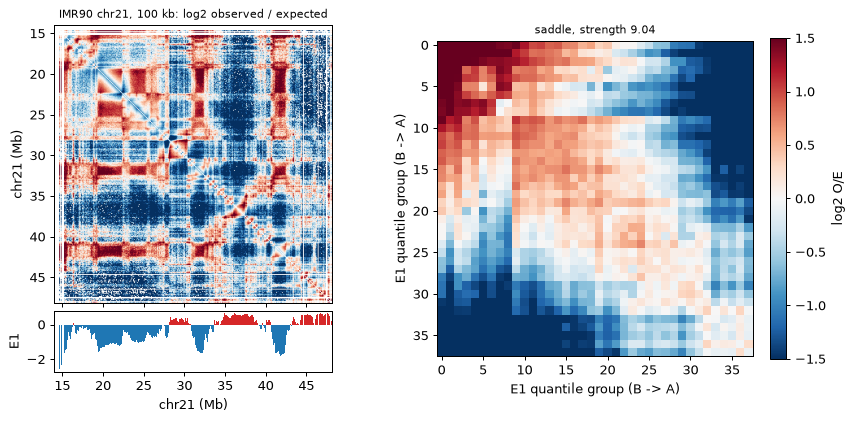

In [5]:
sad = uc.tl.compartment_strength(hic, contacts="bulk_100kb")     # uses hic.results["compartments.eig"]
print(f"saddle strength {sad['strength']:.2f}: AA {sad['AA']:.2f}, BB {sad['BB']:.2f}, AB {sad['AB']:.2f} "
      f"(mean observed / expected; corners of {sad['corner_groups']} groups)")

bins100, M100 = contact_matrix(hic, "bulk_100kb", chrom="chr21")
OE = observed_over_expected(M100)
lo = bins100.index[bins100["start"] >= 14_000_000][0]          # skip the unmappable short arm
OE = OE[lo:, lo:]
e1 = bins100.iloc[lo:].merge(comp[["start", "E1"]], on="start", how="left")["E1"].to_numpy()
mb = bins100["start"].to_numpy()[lo:] / 1e6

fig, (ax, axs) = plt.subplots(1, 2, figsize=(11, 5))
ax.imshow(np.log2(OE), cmap="RdBu_r", vmin=-2, vmax=2, extent=[mb[0], mb[-1] + 0.1, mb[-1] + 0.1, mb[0]])
ax.set_title("IMR90 chr21, 100 kb: log2 observed / expected", fontsize=9); ax.tick_params(labelbottom=False)
ax.set_ylabel("chr21 (Mb)")
axt = make_axes_locatable(ax).append_axes("bottom", size="22%", pad=0.08, sharex=ax)   # aligned with the map
axt.bar(mb + 0.05, np.nan_to_num(e1), width=0.1, color=np.where(np.nan_to_num(e1) > 0, "C3", "C0"))
axt.set_ylabel("E1"); axt.set_xlabel("chr21 (Mb)")
S = np.log2(sad["saddle"][1:-1, 1:-1])
im = axs.imshow(S, cmap="RdBu_r", norm=TwoSlopeNorm(0, -1.5, 1.5))
axs.set_title(f"saddle, strength {sad['strength']:.2f}", fontsize=9)
axs.set_xlabel("E1 quantile group (B -> A)"); axs.set_ylabel("E1 quantile group (B -> A)")
fig.colorbar(im, ax=axs, fraction=0.046, label="log2 O/E")
plt.show()

E1 follows the checkerboard of the observed / expected map: its sign changes where the map switches between
the two interaction patterns, and the saddle shows A–A and B–B contacts enriched over A–B.  On chr21 the B–B
corner dominates (3.3 against 1.1 for A–A: the long gene-poor B stretch of 15–28 Mb), so a strength measured
on one chromosome is not comparable with a genome-wide one — compare strengths on the same chromosomes and
resolution.  (On the same map,
E1 is the same as cooltools `eigs_cis` to 1e-14, and its A / B labels agree with chromatin tracing of IMR90
chr21 on 94 % of the imaged loci: uchrom-reproducibility `benchmarks/toolkit_parity/hic_structures`.)

## Domains: the insulation score

The insulation score of a bin (Crane et al. 2015) is the contact frequency in a square of `w x w` bins that
slides along the diagonal with its corner on the bin; boundaries between domains are its local minima.
`call_tads(method="insulation")` computes it as cooltools `insulation` does, keeps the minima whose prominence
passes Li's threshold, and returns the domains between consecutive boundaries; the default window is 100 kb.
The boundaries go to `hic.results["tads.insulation.boundaries"]`, the per-bin scores to
`"tads.insulation.score"`.

In [6]:
tads10 = uc.tl.call_tads(hic, method="insulation", contacts="bulk_10kb")                          # 100 kb window
tads25 = uc.tl.call_tads(hic, method="insulation", contacts="bulk_25kb", key_added="tads.insulation_25kb")
for name, t in (("10 kb", tads10), ("25 kb", tads25)):
    print(f"{name}: {len(t)} domains, median {(t['end'] - t['start']).median() / 1000:.0f} kb")
hic.results["tads.insulation.boundaries"].head(3)

10 kb: 88 domains, median 270 kb
25 kb: 69 domains, median 325 kb


,chrom,start,end,bin_index,log2_insulation_score,boundary_strength
0,chr21,15610000,15620000,1561,-0.638568,0.334893
1,chr21,15800000,15810000,1580,-0.783153,1.533151
2,chr21,16200000,16210000,1620,-0.463247,0.561118


**Against Arrowhead.**  `compare_boundaries(cd, query, reference, tol=)` places the boundaries of two domain
tables on the loci of a `ChromData` and reports the fraction of the query boundaries within `tol` loci of a
reference boundary, next to what random loci would give (`chance`).  This `ChromData` holds only the map, so
`contacts=` takes the bins of a linked map as the loci.  Run both ways, the fraction near is the precision
(insulation boundaries near an Arrowhead edge) and the recall (Arrowhead edges near an insulation boundary);
the tolerance is 2 bins.

In [7]:
rows = []
for key, table in (("bulk_10kb", "tads.insulation"), ("bulk_25kb", "tads.insulation_25kb")):
    p = compare_boundaries(hic, table, arrowhead, tol=2, contacts=key)       # loci: the bins of the map
    r = compare_boundaries(hic, arrowhead, table, tol=2, contacts=key)
    rows.append({"map": key, "boundaries": p["n_query"], "Arrowhead edges": r["n_query"],
                 "precision": p["fraction_near"], "precision by chance": p["chance"],
                 "recall": r["fraction_near"], "recall by chance": r["chance"]})
pd.DataFrame(rows).round(2)

,map,boundaries,Arrowhead edges,precision,precision by chance,recall,recall by chance
0,bulk_10kb,87,152,0.84,0.13,0.66,0.09
1,bulk_25kb,68,138,0.94,0.28,0.67,0.18


Most insulation boundaries sit at an Arrowhead edge, several times the chance level.  The recall is lower
because Arrowhead domains are nested — an edge inside a larger domain is often a weak insulation minimum.

## Loops: HiCCUPS and Mustache

**HiCCUPS** (Rao et al. 2014) tests every pixel near the diagonal against four local backgrounds (donut,
lower-left, vertical, horizontal) with a Poisson model and a false discovery rate per expected-count chunk,
clusters the enriched pixels and keeps the summits that pass the Rao 2014 filters; its kernel sizes follow the
resolution.  A list of maps calls at each resolution and merges them as Juicer does.  **Mustache** (Roayaei
Ardakany et al. 2020) normalises every diagonal to local z-scores and finds loops as blobs in a Gaussian scale
space.  Both write a pair table (`chrom1, start1, end1, chrom2, start2, end2`, plus their statistics) to
`hic.results` and `hic.intervals`.

`match_loops(reference, calls, tol=25_000)` says which loops of `reference` were called (both anchors within
25 kb): with the published loops as reference it gives the recall, with the calls as reference the precision.

In [8]:
runs = [("HiCCUPS", "hiccups", "bulk_10kb"), ("HiCCUPS", "hiccups", "bulk_5kb"),
        ("HiCCUPS", "hiccups", ["bulk_5kb", "bulk_10kb"]),
        ("Mustache", "mustache", "bulk_10kb"), ("Mustache", "mustache", "bulk_5kb")]
rows = []
for name, method, maps in runs:
    label = "+".join(m.removeprefix("bulk_") for m in maps) if isinstance(maps, list) else maps.removeprefix("bulk_")
    t0 = time.time()
    loops = uc.tl.call_loops(hic, method=method, contacts=maps, key_added=f"loops.{method}.{label}")
    rows.append({"caller": name, "map": label, "loops": len(loops), "seconds": time.time() - t0,
                 "recall": match_loops(published_loops, loops).mean(), "precision": match_loops(loops, published_loops).mean()})
pd.DataFrame(rows).round(2)

,caller,map,loops,seconds,recall,precision
0,HiCCUPS,10kb,94,0.23,0.76,0.74
1,HiCCUPS,5kb,65,0.33,0.60,0.86
2,HiCCUPS,5kb+10kb,99,0.56,0.79,0.74
3,Mustache,10kb,157,0.24,0.72,0.42
4,Mustache,5kb,215,0.60,0.95,0.41


HiCCUPS at 10 kb recovers three quarters of the published loops with three quarters of its calls among them;
merging 5 and 10 kb, as the published list did, adds a few.  Mustache calls more loops: at 5 kb nearly all the
published ones, but fewer than half of its calls are in the published list — its extra calls are not
necessarily wrong (a different method on the same map), but they are not confirmed here.  (Against the
reference implementations on the same maps: HiCCUPS' enriched pixels are identical to cooltools `dots`, and
the Mustache calls agree with mustache-hic within 2 bins for 89–96 % of them.)

## A region of the map with the calls

The 10 kb map of chr21:28–31 Mb (`read_band(...).dense(lo, hi)`: the balanced pixels of a band, as a dense
block): above the diagonal the published calls (Arrowhead domains, HiCCUPS loops), below it the U-Chrom calls
(insulation domains, HiCCUPS loops at 10 kb).

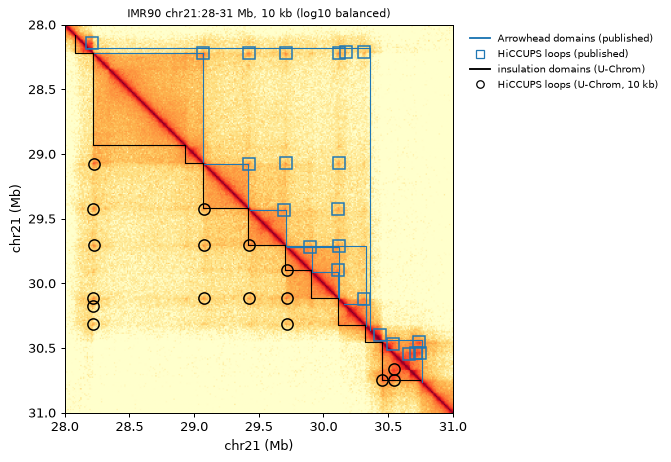

In [9]:
R0, R1, RES = 28_000_000, 31_000_000, 10_000
band = read_band(hic, "bulk_10kb", chrom="chr21", max_dist=R1 - R0)
lo, hi = R0 // RES, R1 // RES
M = band.dense(lo, hi)
x0, x1 = R0 / 1e6, R1 / 1e6

def in_view(t, a="start", b="end"):
    return t[(t[a] >= R0) & (t[b] <= R1)]

fig, ax = plt.subplots(figsize=(6, 5.6))
ax.imshow(np.log10(M + 1e-5), cmap="YlOrRd", vmin=-3.2, vmax=-0.8, extent=[x0, x1, x1, x0])
for t, upper, color in ((in_view(arrowhead), True, "C0"), (in_view(hic.results["tads.insulation"]), False, "k")):
    for s, e in zip(t["start"] / 1e6, t["end"] / 1e6):        # domain outlines: above / below the diagonal
        xs, ys = ([s, e, e], [s, s, e]) if upper else ([s, s, e], [s, e, e])
        ax.plot(xs, ys, color=color, lw=0.9)
for t, upper, kw in ((in_view(published_loops, "start1", "end2"), True, dict(marker="s", mec="C0")),
                     (in_view(hic.results["loops.hiccups.10kb"], "start1", "end2"), False, dict(marker="o", mec="k"))):
    a = (t["start1"] + t["end1"]) / 2e6; b = (t["start2"] + t["end2"]) / 2e6
    ax.plot(*((b, a) if upper else (a, b)), ls="none", mfc="none", ms=9, mew=1.2, **kw)
ax.set_xlim(x0, x1); ax.set_ylim(x1, x0)
ax.set_xlabel("chr21 (Mb)"); ax.set_ylabel("chr21 (Mb)")
ax.set_title("IMR90 chr21:28-31 Mb, 10 kb (log10 balanced)", fontsize=9)
ax.legend(handles=[Line2D([], [], color="C0", label="Arrowhead domains (published)"),
                   Line2D([], [], ls="none", marker="s", mfc="none", mec="C0", label="HiCCUPS loops (published)"),
                   Line2D([], [], color="k", label="insulation domains (U-Chrom)"),
                   Line2D([], [], ls="none", marker="o", mfc="none", mec="k", label="HiCCUPS loops (U-Chrom, 10 kb)")],
          loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, frameon=False)
plt.show()

## Pileup of known loops (APA)

A loop that is too weak to call can still show in the average.  `pileup` cuts a window around every pair (±10
bins), divides each pixel by the expected contact at its separation and aggregates them (aggregate peak
analysis, Rao et al. 2014).  The score `apa` is the centre over the mean of the lower-left corner (P2LL, > 1
when the loops are enriched), `zscore_ll` the centre's z-score in that corner.  Pairs whose window would touch
the diagonal are left out (the anchors must be at least 2 × 10 + 2 bins apart).  As a control, `shifts=` piles
up the same loops moved along the chromosome (same separations, other positions; here by ±0.5 and ±1 Mb):
`control` is their mean score, near 1 when the enrichment belongs to the loops.

In [10]:
SHIFTS = (-1_000_000, -500_000, 500_000, 1_000_000)
apa = uc.tl.pileup(hic, published_loops, contacts="bulk_10kb", shifts=SHIFTS, key_added="pileup.published")
print(f"{apa['n']} of {len(published_loops)} published loops piled up (the others are closer than "
      f"{2 * apa['flank_bins'] + 2} bins): APA {apa['apa']:.2f}, z-score {apa['zscore_ll']:.1f}; "
      f"shifted: {apa['control']:.2f} ({', '.join(f'{d / 1e6:+g} Mb {v:.2f}' for d, v in apa['controls'].items())})")

52 of 92 published loops piled up (the others are closer than 22 bins): APA 4.21, z-score 32.2; shifted: 0.94 (-1 Mb 0.98, -0.5 Mb 0.80, +0.5 Mb 0.95, +1 Mb 1.04)


## Sequencing depth: calling needs bulk depth, pileups do not

Single-cell and pseudo-bulk maps hold a few percent of the contacts of a bulk map like this one (10.3 M
contacts on chr21).  To see what depth does, `thin_map` thins the raw 5 kb map — every contact kept with
probability *f* (binomial thinning of the pixel counts), written and linked to `hic` as `bulk_<f>pct` — which
`rebin_map` sums to 10 kb and balances; then the same calls and the same pileup, with its shifted control.

In [11]:
rows = []
for frac in (1.0, 0.2, 0.05, 0.02):
    key = "bulk_10kb"
    if frac < 1:
        pct = f"{100 * frac:g}pct"
        thin_map(hic, "bulk", fraction=frac, balance=False, out=OUT / f"IMR90_chr21_5kb_{pct}.cool",
                 key_added=f"bulk_{pct}")                       # raw 5 kb counts, thinned with seed 0
        rebin_map(hic, f"bulk_{pct}", resolution=10_000, out=OUT / f"IMR90_chr21_10kb_{pct}.cool")  # -> bulk_<pct>_10kb
        key = f"bulk_{pct}_10kb"
    row = {"depth": f"{frac:.0%}", "contacts": int(open_map(hic, key).info["sum"])}
    for method in ("hiccups", "mustache"):
        loops = uc.tl.call_loops(hic, method=method, contacts=key, key_added=None)
        row[f"{method} loops"] = len(loops)
        row[f"{method} recall"] = match_loops(published_loops, loops).mean()
    a = uc.tl.pileup(hic, published_loops, contacts=key, shifts=SHIFTS, key_added=None)
    row["APA published"], row["z-score"], row["APA shifted"] = a["apa"], a["zscore_ll"], a["control"]
    row["matrix"] = a["matrix"]
    rows.append(row)
depth = pd.DataFrame(rows)
depth.drop(columns="matrix").round(2)

,depth,contacts,hiccups loops,hiccups recall,mustache loops,mustache recall,APA published,z-score,APA shifted
0,100%,10266877,94,0.76,157,0.72,4.21,32.22,0.94
1,20%,2054196,30,0.33,73,0.54,4.25,28.38,1.02
2,5%,514023,1,0.01,10,0.11,3.84,21.92,0.98
3,2%,205039,0,0.00,0,0.00,4.67,19.06,0.61


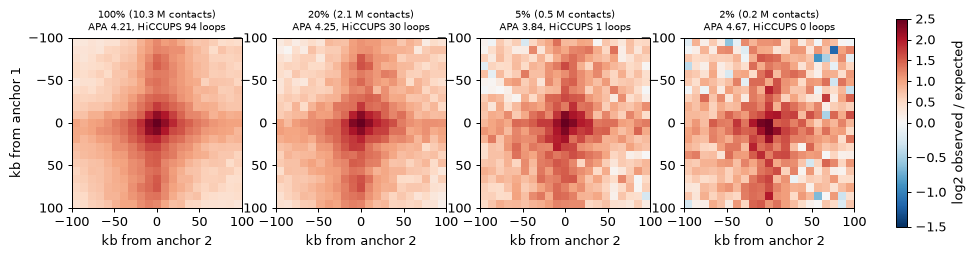

total run time 17 s


In [12]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, (_, r) in zip(axes, depth.iterrows()):
    im = ax.imshow(np.log2(r["matrix"]), cmap="RdBu_r", norm=TwoSlopeNorm(0, -1.5, 2.5),
                   extent=[-100, 100, 100, -100])
    ax.set_title(f"{r['depth']} ({r['contacts'] / 1e6:.1f} M contacts)\nAPA {r['APA published']:.2f}, "
                 f"HiCCUPS {r['hiccups loops']} loops", fontsize=8)
    ax.set_xlabel("kb from anchor 2")
axes[0].set_ylabel("kb from anchor 1")
fig.colorbar(im, ax=axes, fraction=0.015, label="log2 observed / expected")
plt.show()
print(f"total run time {time.time() - T0:.0f} s")

Loop calls fade quickly with depth: at a fifth of the contacts HiCCUPS finds a third of the published loops,
at 5 % one, at 2 % none; Mustache keeps half of them at 20 % and a tenth at 5 %.  The pileup of the same loops
stays enriched at every depth — the centre pixel stays about four times the lower-left corner (APA 3.8–4.7),
while the shifted loops stay at or below 1; only its z-score falls as the map gets noisier — so in a shallow
map (a cell-type pseudo-bulk, a few deep single cells) known loops can be **scored**, not called.  Domains and compartments
need fewer contacts than loops — on the same thinned maps, 88 % of the full-depth insulation boundaries (25 kb)
are still found at 2 % depth (uchrom-reproducibility `benchmarks/toolkit_parity/hic_structures/README.md`) — but the saddle strength of a shallow
map is inflated (+16 % at 2 %), so strengths are compared at matched depth; the
`pseudobulk` tutorial does that.

## Notes

- **Which method**: compartments and insulation work on any map with enough contacts per bin at their
  resolution (100 kb and 10–25 kb here); HiCCUPS is the conservative loop caller (most calls in the published
  list), Mustache the sensitive one; on a shallow map, pile up known loops instead of calling.
- **Larger maps**: everything above reads the map as a band (`read_band`), never as a dense matrix — the
  same calls on IMR90 chr1 at 5 kb (49,851 bins) take seconds to tens of seconds
  (uchrom-reproducibility `benchmarks/toolkit_parity/hic_structures/README.md`).
- **Citations**: Lieberman-Aiden et al. 2009 (eigenvector); Crane et al. 2015 (insulation); Rao et al. 2014
  (HiCCUPS, APA, Arrowhead and the data); Roayaei Ardakany et al. 2020 (Mustache); Open2C 2024 (cooltools,
  the reference formulations).

## Next steps

- `pseudobulk` — per-cell maps of single-cell Hi-C summed per cell type, and compartments compared at matched
  depth.
- `bulk_reconstruction` — 3-D structures from the same map (MDS, IGM).
- `tad_calling`, `loop_calling`, `compartment` — the same structures from chromatin tracing.